# 01 · Exploratory data analysis

**Question:** which account behaviours precede a credit card default, and how strong is the signal?

Data: 30,000 Taiwanese card holders (Apr–Sep 2005), UCI id 350. Target `default` = default payment in October 2005. All analysis below uses the **training split only**; validation/test rows are kept unseen so they can give honest estimates later.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk import plots
from credit_risk.config import load_config
from credit_risk.data import TARGET, clean, download_raw, load_raw, split

plots.apply_style()
pd.set_option("display.float_format", "{:.3f}".format)
cfg = load_config()

In [2]:
df = clean(load_raw(download_raw(cfg.data.url, cfg.data.raw_path)))
train, valid, test = split(df, cfg.data.test_size, cfg.data.valid_size, cfg.seed)
print(
    f"all rows: {len(df):,} | train: {len(train):,} | valid: {len(valid):,} | test: {len(test):,}"
)
print(f"default rate: {df[TARGET].mean():.1%}")
train.describe().T[["mean", "std", "min", "50%", "max"]]

all rows: 30,000 | train: 19,200 | valid: 4,800 | test: 6,000
default rate: 22.1%


,mean,std,min,50%,max
ID,14961.941,8637.813,1.000,14956.500,29998.000
LIMIT_BAL,167418.542,129498.158,10000.000,140000.000,800000.000
SEX,1.605,0.489,1.000,2.000,2.000
EDUCATION,1.840,0.745,1.000,2.000,4.000
MARRIAGE,1.560,0.521,1.000,2.000,3.000
AGE,35.395,9.196,21.000,34.000,75.000
PAY_1,-0.014,1.117,-2.000,0.000,8.000
PAY_2,-0.138,1.195,-2.000,0.000,8.000
PAY_3,-0.169,1.196,-2.000,0.000,8.000
PAY_4,-0.221,1.167,-2.000,0.000,8.000


## Data quality

* No missing values; IDs are unique (enforced by the pandera schema in `src/credit_risk/schema.py`).
* `EDUCATION` contains undocumented codes 0/5/6 and `MARRIAGE` contains 0 → merged into *other* in `clean()`.
* `BILL_AMT` can be negative (customer overpaid) — this is valid and kept.
* Classes are imbalanced (~22 % defaults), so accuracy is a poor metric: we use ROC-AUC, PR-AUC, KS and, most importantly, **expected business cost**.

In [3]:
raw = load_raw(cfg.data.raw_path)
print("missing values:", int(raw.isna().sum().sum()))
print("undocumented EDUCATION codes:", int((~raw["EDUCATION"].between(1, 4)).sum()))
print("undocumented MARRIAGE codes :", int((~raw["MARRIAGE"].between(1, 3)).sum()))
print(
    "negative bill amounts       :",
    int((raw[[f"BILL_AMT{i}" for i in range(1, 7)]] < 0).any(axis=1).sum()),
)

missing values: 0
undocumented EDUCATION codes: 345
undocumented MARRIAGE codes : 54
negative bill amounts       : 1930


## Repayment status is the dominant signal

`PAY_1` is the repayment status in September 2005 (−2 no consumption, −1 paid in full, 0 revolving, 1–9 months of delay).

,default_rate,n
PAY_1,,
-2,0.125,1745
-1,0.165,3659
0,0.126,9379
1,0.344,2410
2,0.695,1724
3,0.789,199
4,0.674,46


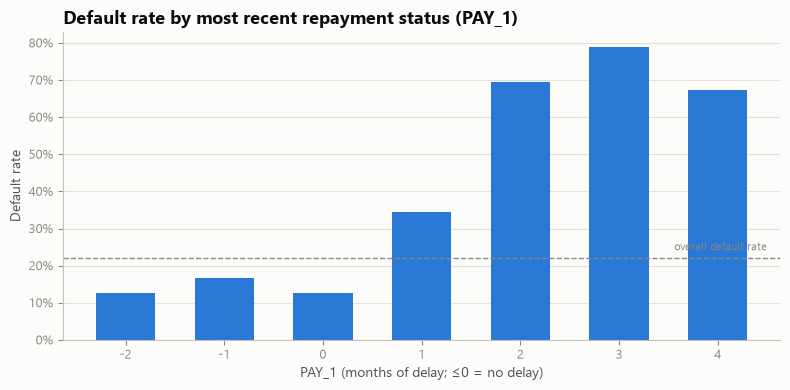

In [4]:
rate = (
    train.groupby("PAY_1")[TARGET]
    .agg(["mean", "size"])
    .rename(columns={"mean": "default_rate", "size": "n"})
)
rate = rate[rate["n"] >= 30]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(rate.index.astype(str), rate["default_rate"], color=plots.SERIES[0], width=0.6)
ax.axhline(train[TARGET].mean(), color=plots.MUTED, ls="--", lw=1)
ax.text(
    len(rate) - 0.5,
    train[TARGET].mean() + 0.02,
    "overall default rate",
    ha="right",
    color=plots.MUTED,
    fontsize=8,
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.set(
    title="Default rate by most recent repayment status (PAY_1)",
    xlabel="PAY_1 (months of delay; ≤0 = no delay)",
    ylabel="Default rate",
)
fig.tight_layout()
fig.savefig("reports/figures/eda_default_by_pay1.png", dpi=150)
rate

Customers who are already **2 months late** default about 70 % of the time, versus 13–17 % for customers with no delay (PAY_1 ≤ 0). Recent delinquency is by far the strongest predictor — the engineered features `months_delayed`, `max_delay` and `delay_trend` summarise this history.

,mean,size
util_bucket,,
≤0,0.252,1668
0–25%,0.166,7368
25–50%,0.219,2295
50–75%,0.254,2292
75–100%,0.260,4240
>100%,0.308,1337


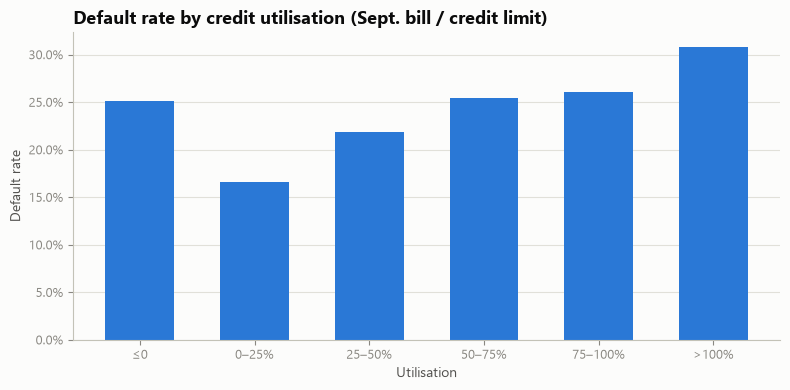

In [5]:
from credit_risk.features import build_features

x = build_features(train).assign(default=train[TARGET].to_numpy())
x["util_bucket"] = pd.cut(
    x["util_recent"],
    [-np.inf, 0, 0.25, 0.5, 0.75, 1.0, np.inf],
    labels=["≤0", "0–25%", "25–50%", "50–75%", "75–100%", ">100%"],
)
u = x.groupby("util_bucket", observed=True)["default"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(u.index.astype(str), u["mean"], color=plots.SERIES[0], width=0.6)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="x", visible=False)
ax.set(
    title="Default rate by credit utilisation (Sept. bill / credit limit)",
    xlabel="Utilisation",
    ylabel="Default rate",
)
fig.tight_layout()
fig.savefig("reports/figures/eda_default_by_utilisation.png", dpi=150)
u

The relationship is **U-shaped**: risk rises steadily with utilisation above 25 %, but customers with a zero or negative balance also default more often than light users. An inactive card is not automatically a safe one. Tree models capture this kind of non-linearity naturally; the logistic-regression baseline cannot without manual binning.

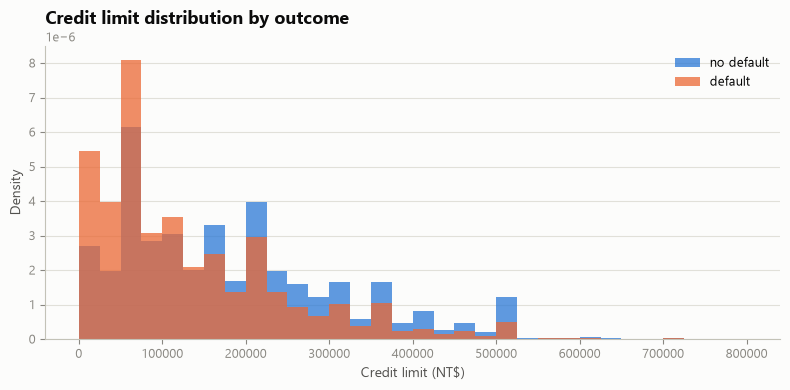

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 800_000, 33)
ax.hist(
    train.loc[train[TARGET] == 0, "LIMIT_BAL"],
    bins=bins,
    density=True,
    alpha=0.75,
    color=plots.SERIES[0],
    label="no default",
)
ax.hist(
    train.loc[train[TARGET] == 1, "LIMIT_BAL"],
    bins=bins,
    density=True,
    alpha=0.75,
    color=plots.SERIES[1],
    label="default",
)
ax.legend()
ax.grid(axis="x", visible=False)
ax.set(title="Credit limit distribution by outcome", xlabel="Credit limit (NT$)", ylabel="Density")
fig.tight_layout()

Defaulters are concentrated at **low credit limits** — the bank's own limit assignment already encodes risk information, which also makes `LIMIT_BAL` a potential *proxy* for protected attributes (see the fairness audit in notebook 02).

In [7]:
prot = pd.DataFrame(
    {
        "sex": train.groupby("SEX")[TARGET].mean().rename({1: "male", 2: "female"}),
    }
).T
display(prot)
display(
    train.groupby(
        pd.cut(train["AGE"], [0, 29, 39, 49, 200], labels=["<30", "30-39", "40-49", "50+"]),
        observed=True,
    )[TARGET]
    .mean()
    .to_frame("default_rate")
    .T
)

SEX,male,female
sex,0.241,0.208


AGE,<30,30-39,40-49,50+
default_rate,0.232,0.202,0.225,0.255


## Takeaways for modelling

1. **Delinquency history** (`PAY_*`) carries most of the signal; utilisation and repayment ratios add to it.
2. Base default rates differ by sex and age. The model **does not use** sex, marital status or age as inputs, but outcomes are still audited per group because other features can act as proxies.
3. With a 22 % positive class and asymmetric error costs, the decision threshold must be chosen on business cost — not left at 0.5.